# Rank Adaptive Optimization for Memory Efficient Neural Surrogates of Navier Stokes Flow

*Teaching a neural network to simulate fluids, and making it cheap enough to train many times over.*

---

## The Idea

Simulating fluid flow means solving the **Navier stokes equations**. They are accurate but slow, and the cost climbs steeply as the grid gets finer. A **neural surrogate** learns to imitate the solver: give it the input field, and it predicts the flow in a single forward pass.

To trust a surrogate, we also want to know when it is unsure. The standard way is to train an **ensemble** of $K$ networks and look at how much they disagree. This works well, but it multiplies the training memory by $K$.

Most of that memory goes to the optimizer. Adam keeps two extra numbers (a running mean $m$ and a running variance $v$) for every parameter, so its states cost about $2\times$ the model itself. **GaLore** shrinks this by projecting each layer's gradient $G \in \mathbb{R}^{m \times n}$ onto a small subspace of fixed rank $r$:

$$
R_t = P_t^{\top} G_t, \qquad P_t \in \mathbb{R}^{m \times r}, \quad r \ll \min(m, n)
$$

The optimizer states now live in the small $R_t$ instead of the full $G_t$.

## The Problem

GaLore uses **one fixed rank $r$ for every layer, for the whole training run**. That is a blunt choice:

- Some layers need a rich gradient and get squeezed too hard.
- Other layers could manage with far less and waste memory.
- The gradient's useful rank also changes as training goes on.

## Our Goal

Build an optimizer that chooses the rank **per layer and per step**:

$$
r = r_{\ell}(t) \quad \text{for layer } \ell \text{ at training step } t
$$

We then test it on a real task and compare it against standard Adam and fixed-rank GaLore.

| What we measure | Question we ask |
|---|---|
| **Memory** | How much optimizer memory do we save? |
| **Speed** | How fast does training run? |
| **Accuracy** | Does the surrogate still match the true solver? |
| **Surrogate vs. solver** | How much faster is inference than the original Navier-Stokes solver? |

**The payoff:** cheaper training makes larger ensembles affordable. That gives us uncertainty estimates, and those can tell us which simulations are worth running next (**active learning**).



# The Dataset

Before building anything, let's look at what the network will actually be learning from.

---

## What is in the data?

The data comes as a Python dictionary with two keys:

| Key | Meaning | Role |
|---|---|---|
| `x` | the **input field** given to the Navier-Stokes solver | what the network sees |
| `y` | the **output field** the solver produces | what the network must predict |

Every sample is a pair $(x_i, y_i)$, and each one is a $128 \times 128$ grid of numbers, like a small grayscale image where every pixel holds the value of a physical quantity at that point in space:

$$
x_i,\, y_i \in \mathbb{R}^{128 \times 128}
$$

The solver is a function that turns $x$ into $y$. Our surrogate network $f_\theta$ tries to learn that same mapping:

$$
f_\theta(x_i) \approx y_i
$$

## Size and split

| Split | Samples | Shape of `x` | Shape of `y` |
|---|---|---|---|
| **Train** | 10,000 | `[10000, 128, 128]` | `[10000, 128, 128]` |
| **Test** | 2,000 | `[2000, 128, 128]` | `[2000, 128, 128]` |

Each field holds $128 \times 128 = 16{,}384$ values. Across the training set, one tensor has $10{,}000 \times 16{,}384 \approx 164$ million numbers, which is roughly 650 MB in float32. That is small for a dataset, but large enough that memory matters once we start training.

## Summary statistics

| | Min | Max | Mean | Std |
|---|---|---|---|---|
| **Train `x`** | -0.759 | 0.817 | 0.000 | 0.154 |
| **Train `y`** | -3.489 | 3.928 | 0.000 | 0.708 |
| **Test `x`** | -0.762 | 0.750 | 0.000 | 0.154 |
| **Test `y`** | -3.631 | 3.627 | 0.000 | 0.706 |

## What these numbers tell us

1. **Everything is centered.** All means are $\approx 0$, so the fields fluctuate around zero with no constant offset.
2. **The output is wider than the input.** The ratio of spreads is
   $$\frac{\sigma_y}{\sigma_x} = \frac{0.708}{0.154} \approx 4.6$$
   so the solver amplifies the signal. The network has to produce values about $4.6\times$ larger than what it receives.
3. **Train and test match.** The statistics are almost identical across the two splits, which means the test set comes from the same distribution. Test accuracy will therefore be a fair measure of how well the surrogate generalizes.
4. **Scales are not unit-sized.** Since $\sigma_y \approx 0.7$ and the extremes reach about $\pm 3.9$ (over five standard deviations), we will standardize the data before training so the optimizer sees well-behaved values:

$$
\tilde{y} = \frac{y - \mu_y}{\sigma_y}
$$


In [ ]:
# neuralop (FNO) and torchinfo ship with the Kaggle image; install only if missing
import importlib.util
missing = [pkg for mod, pkg in (("neuralop", "neuraloperator"), ("torchinfo", "torchinfo"))
           if importlib.util.find_spec(mod) is None]
if missing:
    pkgs = " ".join(missing)
    print(f"[INFO] installing: {pkgs}")
    !pip install -q {pkgs}
else:
    print("[INFO] neuralop and torchinfo already installed")

In [1]:
import torch, sys

print(f"[INFO] {sys.version}")
print(f"[INFO] torch version: {torch.__version__}")
print(f"[INFO] cuda available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"[INFO] GPU Name: {torch.cuda.get_device_name(0)}")

[INFO] 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[INFO] torch version: 2.11.0+cu128
[INFO] cuda available: True
[INFO] GPU Name: Tesla T4


In [ ]:
import torch, glob, os, hashlib, tarfile, urllib.request

FILES = ("nsforcing_train_128.pt", "nsforcing_test_128.pt")
# Same archive that neuralop's NavierStokesDataset downloads (Zenodo record 12825163)
ZENODO_URL = "https://zenodo.org/api/records/12825163/files/nsforcing_128.tgz/content"
ZENODO_MD5 = "70a389207ac93935d5ff3d4289d43581"
ZENODO_SIZE = 1450200928   # bytes
DOWNLOAD_DIR = "/kaggle/working/data"

def has_files(d):
    return all(os.path.exists(f"{d}/{f}") for f in FILES)

def download_from_zenodo(dest):
    """Stream the archive, verify its md5, extract the .pt files into dest, delete the archive."""
    os.makedirs(dest, exist_ok=True)
    tgz, md5 = f"{dest}/nsforcing_128.tgz", hashlib.md5()
    with urllib.request.urlopen(ZENODO_URL) as r, open(tgz, "wb") as fh:
        size, done, shown = int(r.headers.get("Content-Length") or ZENODO_SIZE), 0, 0
        while chunk := r.read(1 << 22):
            fh.write(chunk); md5.update(chunk); done += len(chunk)
            if done * 10 // size > shown:                      # progress every 10%
                shown = done * 10 // size
                print(f"[INFO] downloaded {done / 1e9:.2f} / {size / 1e9:.2f} GB")
    if md5.hexdigest() != ZENODO_MD5:
        raise RuntimeError(f"md5 mismatch for {tgz}: {md5.hexdigest()}")
    with tarfile.open(tgz) as tar:
        tar.extractall(dest, members=[m for m in tar.getmembers() if os.path.basename(m.name) in FILES],
                    filter="data")
    os.remove(tgz)
    for f in FILES:                                            # in case the archive has a subfolder
        hit = glob.glob(f"{dest}/**/{f}", recursive=True)[0]
        if hit != f"{dest}/{f}":
            os.replace(hit, f"{dest}/{f}")

# 1. a Kaggle dataset attached to the notebook (either mount layout)
candidates = ["/kaggle/input/datasets/paritycodes/ns-forcing-128", "/kaggle/input/ns-forcing-128"]
candidates += sorted({os.path.dirname(p) for p in glob.glob(f"/kaggle/input/**/{FILES[0]}", recursive=True)})
data_dir = next((d for d in candidates if has_files(d)), None)
source = f"Kaggle input ({data_dir})"
# 2. otherwise the public Zenodo copy
if data_dir is None:
    data_dir = DOWNLOAD_DIR
    if has_files(data_dir):
        source = f"earlier Zenodo download ({data_dir})"
    else:
        print(f"[INFO] dataset not found under /kaggle/input; downloading from Zenodo to {data_dir}")
        download_from_zenodo(data_dir)
        source = f"Zenodo record 12825163 ({data_dir})"
print(f"[INFO] loading data from: {source}")

train_dataset = torch.load(f"{data_dir}/nsforcing_train_128.pt")
test_dataset = torch.load(f"{data_dir}/nsforcing_test_128.pt")

for split, ds in (("train", train_dataset), ("test", test_dataset)):
    for key in ("x", "y"):
        t = ds[key].float()
        print(f"[INFO] {split} {key}: shape {tuple(t.shape)}  min {t.min():.3f}  max {t.max():.3f}  "
              f"mean {t.mean():.3f}  std {t.std():.3f}")

# stop before any training if the data differs from the team's (dataset section)
expected = {"train": ((10000, 128, 128), 0.708), "test": ((2000, 128, 128), 0.706)}
problems = []
for split, ds in (("train", train_dataset), ("test", test_dataset)):
    shape, y_std = expected[split]
    for key in ("x", "y"):
        if tuple(ds[key].shape) != shape:
            problems.append(f"{split} {key} shape {tuple(ds[key].shape)}, expected {shape}")
    measured = ds["y"].float().std().item()
    if abs(measured - y_std) > 0.01:
        problems.append(f"{split} y std {measured:.4f}, expected {y_std} ± 0.01")
if problems:
    raise RuntimeError("Data does not match the team's dataset; stopping before training:\n  "
                       + "\n  ".join(problems))
print("[INFO] data check passed: shapes and y std match the team's dataset")

In [3]:
import pandas as pd

def datasetInfo(dataset, name="dataset"):
    if not isinstance(dataset, dict):
        print("[INFO] Not a dict dataset")
        return None

    rows = []
    for key, t in dataset.items():
        rows.append({
            "split": name,
            "key": key,
            "samples": t.shape[0],
            "shape": str(tuple(t.shape)),
            "min": t.min().item(),
            "max": t.max().item(),
            "mean": t.mean().item(),
            "std": t.std().item(),
        })
    return pd.DataFrame(rows)

In [4]:
info = pd.concat(
    [datasetInfo(train_dataset, "train"), datasetInfo(test_dataset, "test")],
    ignore_index=True,
)

info.style.format({
    "min": "{:.3f}", "max": "{:.3f}",
    "mean": "{:.2e}", "std": "{:.3f}",
}).hide(axis="index")

split,key,samples,shape,min,max,mean,std
train,x,10000,"(10000, 128, 128)",-0.759,0.817,1.02e-10,0.154
train,y,10000,"(10000, 128, 128)",-3.489,3.928,2.03e-12,0.708
test,x,2000,"(2000, 128, 128)",-0.762,0.750,-4.49e-10,0.154
test,y,2000,"(2000, 128, 128)",-3.631,3.627,-4.10e-11,0.706


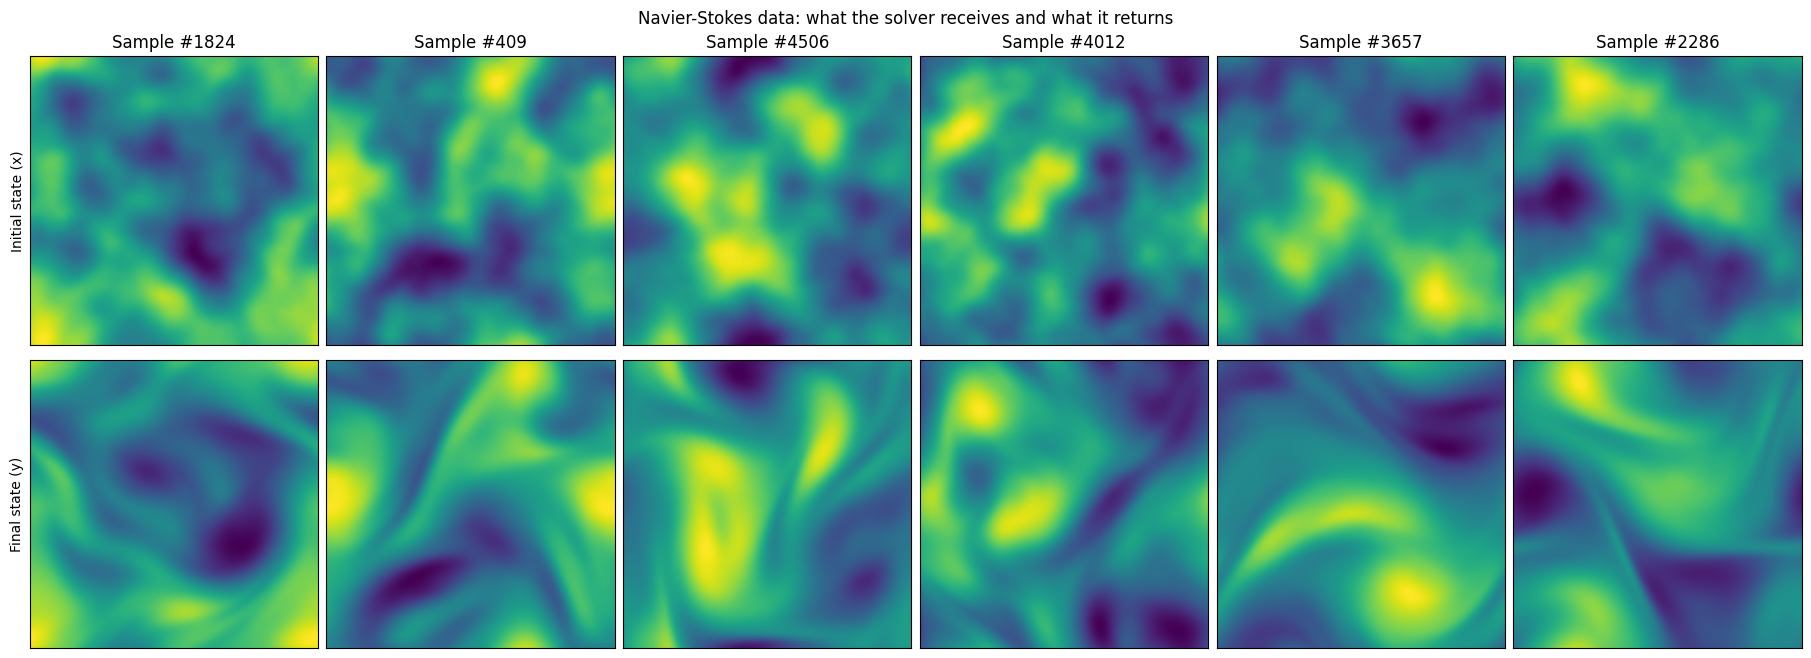

In [5]:
import random
import matplotlib.pyplot as plt

random.seed(42)
idx = random.sample(range(len(train_dataset['x'])), 6)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5), constrained_layout=True)

for j, i in enumerate(idx):
    axes[0, j].imshow(train_dataset['x'][i], cmap="viridis", origin="lower")
    axes[1, j].imshow(train_dataset['y'][i], cmap="viridis", origin="lower")
    axes[0, j].set_title(f"Sample #{i}")
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xticks([])
        ax.set_yticks([])

axes[0, 0].set_ylabel("Initial state (x)")
axes[1, 0].set_ylabel("Final state (y)")
fig.suptitle("Navier-Stokes data: what the solver receives and what it returns")
plt.show()

# Data Preparation

The raw fields are not ready for a network yet. In four short steps we split the data, put it on a common scale, give it the shape a convolutional network expects, and serve it in batches.


## Train / validation / test split

The training set is shuffled with a fixed seed (`0`), so the split is the same on every run, and then divided 80/20. The 2,000 test samples are kept untouched.

| Split | Samples | Purpose |
|---|---|---|
| **Train** | 8,000 | fit the network |
| **Validation** | 2,000 | tune settings and watch for overfitting |
| **Test** | 2,000 | final, honest score |


In [6]:
# split

torch.manual_seed(0)

x_train = train_dataset['x'].float()
y_train = train_dataset['y'].float()

x_test = test_dataset['x'].float()
y_test = test_dataset['y'].float()

# random permutation of training data

permutation = torch.randperm(
    len(x_train),
    generator=torch.Generator().manual_seed(0)
)

# apply permutation

x_train_raw, y_train_raw = x_train[permutation], y_train[permutation]

In [7]:
# split training 80% and validation 20%

index_to_end = int(0.8*len(x_train_raw))

x_val, y_val = x_train_raw[index_to_end:], y_train_raw[index_to_end:]
x_train,y_train = x_train_raw[:index_to_end],y_train_raw[:index_to_end]

print(f"[INFO] Dataset split successful.")
print(f"[INFO] Dataset split sizes: Train {len(x_train)}, Test: {len(x_test)}, Validation: {len(x_val)}.")

[INFO] Dataset split successful.
[INFO] Dataset split sizes: Train 8000, Test: 2000, Validation: 2000.


## Standardize

The input `x` has a spread of about 0.15, while the output `y` has about 0.71. We rescale both so they sit on a comparable, unit-sized scale:

$$
\tilde{x} = \frac{x - \mu_x}{\sigma_x}, \qquad \tilde{y} = \frac{y - \mu_y}{\sigma_y}
$$

The means $\mu$ and standard deviations $\sigma$ are computed on the **training set only** and reused for validation and test. Computing them on unseen data would leak information into training and flatter our test scores.

After this step, both fields should show a mean of about 0 and a standard deviation of about 1 on the training set, and values close to those on validation and test.

In [8]:
import pandas as pd

# Normalize Data
def normalize(data, mean, dev):
    return (data - mean) / dev

def statsRow(split, stage, x, y):
    return {
        "split": split, "stage": stage,
        "mean X": x.mean().item(), "mean Y": y.mean().item(),
        "std X": x.std().item(),   "std Y": y.std().item(),
    }

# statistics come from the training set only
x_train_mean, y_train_mean = x_train.mean(), y_train.mean()
x_train_dev,  y_train_dev  = x_train.std(),  y_train.std()

rows = [statsRow("train", "before", x_train, y_train)]

# apply the same train statistics to every split
x_train = normalize(x_train, x_train_mean, x_train_dev)
y_train = normalize(y_train, y_train_mean, y_train_dev)

x_val = normalize(x_val, x_train_mean, x_train_dev)
y_val = normalize(y_val, y_train_mean, y_train_dev)

x_test = normalize(x_test, x_train_mean, x_train_dev)
y_test = normalize(y_test, y_train_mean, y_train_dev)

rows += [
    statsRow("train",      "after", x_train, y_train),
    statsRow("validation", "after", x_val,   y_val),
    statsRow("test",       "after", x_test,  y_test),
]

print("[INFO] Data Normalization Successful.")

stats_table = pd.DataFrame(rows)
display(
    stats_table.style
    .format({"mean X": "{:.2e}", "mean Y": "{:.2e}",
             "std X": "{:.4f}",  "std Y": "{:.4f}"})
    .hide(axis="index")
)

[INFO] Data Normalization Successful.


split,stage,mean X,mean Y,std X,std Y
train,before,3.83e-11,1.86e-12,0.1538,0.7078
train,after,2.59e-10,2.97e-11,1.0000,1.0000
validation,after,2.26e-09,-3.91e-11,1.0008,1.0006
test,after,-2.92e-09,1.86e-12,0.9981,0.9978


## Add a channel dimension

Convolutional layers expect `[batch, channels, height, width]`. Our fields are single-valued grids, so they get one channel:

$$
[N,\ 128,\ 128] \;\longrightarrow\; [N,\ 1,\ 128,\ 128]
$$

In [9]:
import pandas as pd

def shapeInfo(splits, status=None):
    """splits: dict like {"train": (x_train, y_train), ...}"""
    rows = [
        {"split": name, "X shape": str(tuple(x.shape)), "Y shape": str(tuple(y.shape))}
        for name, (x, y) in splits.items()
    ]
    print(f"[INFO] Shapes [{status}]\n")
    display(pd.DataFrame(rows).style.hide(axis="index"))

# before adding the channel dimension
shapeInfo({
    "train":      (x_train, y_train),
    "validation": (x_val,   y_val),
    "test":       (x_test,  y_test),
}, status="Before")

# adding channel dimension (grayscale)
x_train, y_train = x_train.unsqueeze(1), y_train.unsqueeze(1)
x_val,   y_val   = x_val.unsqueeze(1),   y_val.unsqueeze(1)
x_test,  y_test  = x_test.unsqueeze(1),  y_test.unsqueeze(1)

# after
shapeInfo({
    "train":      (x_train, y_train),
    "validation": (x_val,   y_val),
    "test":       (x_test,  y_test),
}, status="After")

[INFO] Shapes [Before]



split,X shape,Y shape
train,"(8000, 128, 128)","(8000, 128, 128)"
validation,"(2000, 128, 128)","(2000, 128, 128)"
test,"(2000, 128, 128)","(2000, 128, 128)"


[INFO] Shapes [After]



split,X shape,Y shape
train,"(8000, 1, 128, 128)","(8000, 1, 128, 128)"
validation,"(2000, 1, 128, 128)","(2000, 1, 128, 128)"
test,"(2000, 1, 128, 128)","(2000, 1, 128, 128)"


## Batching

Feeding all 8,000 grids at once would be slow and memory-hungry, so a `DataLoader` serves them in batches of 32. Only the training loader shuffles, which gives the network a new sample order every epoch. Validation and test keep a fixed order.

Each batch has the shape:

$$
\texttt{X}: [32,\ 1,\ 128,\ 128], \qquad \texttt{Y}: [32,\ 1,\ 128,\ 128]
$$

---

**Note:** the network now works in standardized units. Before reporting errors in the solver's real units, we undo the scaling with $y = \sigma_y \tilde{y} + \mu_y$.

In [10]:
# creating data loaders
from torch.utils.data import TensorDataset, DataLoader

batch_size = 32
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(x_val,   y_val),   batch_size=batch_size)
test_loader  = DataLoader(TensorDataset(x_test,  y_test),  batch_size=batch_size)

xb, yb = next(iter(train_loader))
print(f"[INFO] X: {xb.shape}, Y:{yb.shape}")

[INFO] X: torch.Size([32, 1, 128, 128]), Y:torch.Size([32, 1, 128, 128])


# Baseline Models

Before testing our optimizer, we need a surrogate to train. This section sets up the network that every optimizer will be compared on.

## Fourier Neural Operator (FNO)

Our baseline surrogate is a **Fourier Neural Operator**. It learns a mapping from one field to another, here the solver's input grid to its output grid, and it is a standard choice for Navier-Stokes problems.

### The core idea

Each FNO layer works in frequency space. It takes the Fourier transform of the field, keeps only the lowest frequencies, mixes them with learned weights, and transforms back. A small pointwise linear path runs alongside to capture local detail:

$$
v_{\ell+1}(x) = \sigma\Big( W\,v_\ell(x) \;+\; \mathcal{F}^{-1}\big(R \cdot \mathcal{F}(v_\ell)\big)(x) \Big)
$$

where $\mathcal{F}$ is the Fourier transform, $R$ holds the learned frequency weights, $W$ is the local linear path and $\sigma$ is a nonlinearity. Fluid fields are mostly smooth, so most of the signal sits in the low frequencies, and a few of them carry most of the information.

### Our configuration

| Setting | Value | Meaning |
|---|---|---|
| `n_modes` | (16, 16) | keep the 16 x 16 lowest frequencies out of 128 x 128 |
| `hidden_channels` | 64 | width of the network between layers |
| `in_channels` | 1 | one input field |
| `out_channels` | 1 | one predicted field |
| `n_layers` | 4 | number of Fourier layers |

The network lifts the 1-channel input to 64 channels, applies 4 Fourier layers, and projects back down to a 1-channel output:

$$
[N,\,1,\,128,\,128] \;\to\; [N,\,64,\,128,\,128] \;\to\; [N,\,1,\,128,\,128]
$$

### Why this is our baseline

It is accurate and well established for fluid problems. Every optimizer we test (Adam, GaLore, and ours) will train this same architecture, so any difference in the results comes from the optimizer alone.

In [11]:
from neuralop.models import FNO

def FourierNeuralOperator():
    model = FNO(
        n_modes=(16,16),      # choose top 16 frequencies
        hidden_channels=64,
        in_channels = 1,
        out_channels=1,
        n_layers=4,           #hidden layers
    )

    return model


In [12]:
from torchinfo import summary

fno = FourierNeuralOperator()
summary(fno, input_size=(1, 1, 128, 128), depth=3,
        col_names=("input_size", "output_size", "num_params"))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
FNO                                      [1, 1, 128, 128]          [1, 1, 128, 128]          --
├─GridEmbeddingND: 1-1                   [1, 1, 128, 128]          [1, 3, 128, 128]          --
├─ChannelMLP: 1-2                        [1, 3, 128, 128]          [1, 64, 128, 128]         --
│    └─ModuleList: 2-1                   --                        --                        --
│    │    └─Conv1d: 3-1                  [1, 3, 16384]             [1, 128, 16384]           512
│    │    └─Conv1d: 3-2                  [1, 128, 16384]           [1, 64, 16384]            8,256
├─FNOBlocks: 1-3                         [1, 64, 128, 128]         [1, 64, 128, 128]         1,794,720
│    └─ModuleList: 2-14                  --                        --                        (recursive)
│    │    └─Flattened1dConv: 3-3         [1, 64, 128, 128]         [1, 64, 128, 128]         4,096
│    └─Modul

## Convolutional Neural Network (CNN)

Our second baseline is a plain **CNN**. It has no Fourier layers, so it gives the FNO a simple architecture to be compared against.

### The core idea

Each layer slides a small $3 \times 3$ filter over the grid, so every output pixel is computed from its immediate neighbors:

$$
y_{i,j} = \sigma\Big( \sum_{a=-1}^{1}\sum_{b=-1}^{1} w_{a,b}\; x_{i+a,\,j+b} + b_0 \Big)
$$

Stacking layers widens what each pixel can see. With 7 layers of $3 \times 3$ filters, each output pixel depends on a $15 \times 15$ patch of the input:

$$
\text{receptive field} = 1 + 7 \times 2 = 15
$$

### Our configuration

| Setting | Value |
|---|---|
| Conv layers | 7 (1 to 32 channels, five 32 to 32 layers, then 32 to 1) |
| Kernel size | $3 \times 3$ |
| Activation | GELU |
| Padding | circular (the grid wraps around at the edges) |
| Parameters | 46,849 |

The grid size stays $128 \times 128$ throughout. Only the channel count changes:

$$
[N,\,1,\,128,\,128] \;\to\; [N,\,32,\,128,\,128] \;\to\; [N,\,1,\,128,\,128]
$$

In [13]:
# cnn model
import torch, torch.nn as nn

def Cnn():
    return nn.Sequential(
        nn.Conv2d(1,  32, 3, padding=1, padding_mode="circular"), nn.GELU(),   
        nn.Conv2d(32, 32, 3, padding=1, padding_mode="circular"), nn.GELU(),   
        nn.Conv2d(32, 32, 3, padding=1, padding_mode="circular"), nn.GELU(),
        nn.Conv2d(32, 32, 3, padding=1, padding_mode="circular"), nn.GELU(),
        nn.Conv2d(32, 32, 3, padding=1, padding_mode="circular"), nn.GELU(),
        nn.Conv2d(32, 32, 3, padding=1, padding_mode="circular"), nn.GELU(),
        nn.Conv2d(32, 1,  3, padding=1, padding_mode="circular"),         
    )

In [14]:
from torchinfo import summary

cnn = Cnn()
summary(cnn, input_size=(1, 1, 128, 128), depth=2,
        col_names=("input_size", "output_size", "num_params"))


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 1, 128, 128]          [1, 1, 128, 128]          --
├─Conv2d: 1-1                            [1, 1, 128, 128]          [1, 32, 128, 128]         320
├─GELU: 1-2                              [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─Conv2d: 1-3                            [1, 32, 128, 128]         [1, 32, 128, 128]         9,248
├─GELU: 1-4                              [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─Conv2d: 1-5                            [1, 32, 128, 128]         [1, 32, 128, 128]         9,248
├─GELU: 1-6                              [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─Conv2d: 1-7                            [1, 32, 128, 128]         [1, 32, 128, 128]         9,248
├─GELU: 1-8                              [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─Conv2d: 1-9            

## U-Net

Our third baseline is a **U-Net**, built as an upgrade to the plain CNN. The plain CNN only looks at a small window around each pixel. The U-Net shrinks the grid step by step, so deeper layers cover larger regions, and then grows it back to full size.

### The core idea

The network has two halves joined by **skip connections**:

- **Encoder:** convolutions followed by pooling, taking the grid from $128 \times 128$ down to $16 \times 16$ while the channel count grows.
- **Decoder:** upsampling followed by convolutions, taking the grid back up to $128 \times 128$.
- **Skip connections:** each decoder stage is concatenated with the encoder features of the same size, so fine detail is not lost on the way down.

$$
128^2 \xrightarrow{\text{pool}} 64^2 \xrightarrow{\text{pool}} 32^2 \xrightarrow{\text{pool}} 16^2 \xrightarrow{\text{up}} 32^2 \xrightarrow{\text{up}} 64^2 \xrightarrow{\text{up}} 128^2
$$

### Our configuration

| Setting | Value |
|---|---|
| Levels | 3 pooling steps, plus a bottleneck at $16 \times 16$ |
| Channels | 32, 64, 128, 256 |
| Kernel size | $3 \times 3$ |
| Activation | GELU |
| Padding | circular (the grid wraps around at the edges) |
| Downsampling | average pooling |
| Upsampling | bilinear interpolation, followed by a convolution |
| Parameters | 2,140,065 |

The parameter count is much larger than the plain CNN's 46,849, so the comparison between them is not parameter-matched.

In [15]:
# unet model
import torch, torch.nn as nn

def convBlock(in_c, out_c):
    """two 3x3 convs with circular padding"""
    return nn.Sequential(
        nn.Conv2d(in_c,  out_c, 3, padding=1, padding_mode="circular"), nn.GELU(),
        nn.Conv2d(out_c, out_c, 3, padding=1, padding_mode="circular"), nn.GELU(),
    )

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base=32):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8

        # encoder: 128 -> 64 -> 32 -> 16
        self.enc1 = convBlock(in_channels, c1)
        self.enc2 = convBlock(c1, c2)
        self.enc3 = convBlock(c2, c3)
        self.bottleneck = convBlock(c3, c4)
        self.pool = nn.AvgPool2d(2)

        # decoder: upsample, then convolve, then merge with the skip connection
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.up3 = nn.Conv2d(c4, c3, 3, padding=1, padding_mode="circular")
        self.up2 = nn.Conv2d(c3, c2, 3, padding=1, padding_mode="circular")
        self.up1 = nn.Conv2d(c2, c1, 3, padding=1, padding_mode="circular")
        self.dec3 = convBlock(c3 * 2, c3)
        self.dec2 = convBlock(c2 * 2, c2)
        self.dec1 = convBlock(c1 * 2, c1)

        self.head = nn.Conv2d(c1, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)                    # [N, c1, 128, 128]
        e2 = self.enc2(self.pool(e1))        # [N, c2,  64,  64]
        e3 = self.enc3(self.pool(e2))        # [N, c3,  32,  32]
        b  = self.bottleneck(self.pool(e3))  # [N, c4,  16,  16]

        d3 = self.dec3(torch.cat([self.up3(self.up(b)),  e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(self.up(d3)), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(self.up(d2)), e1], dim=1))
        return self.head(d1)                 # [N, 1, 128, 128]

model = UNet()

In [16]:
from torchinfo import summary

model = UNet()
summary(
    model,
    input_size=(1, 1, 128, 128),   # [batch, channels, height, width]
    col_names=("input_size", "output_size", "num_params"),
    depth=2,
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
UNet                                     [1, 1, 128, 128]          [1, 1, 128, 128]          --
├─Sequential: 1-1                        [1, 1, 128, 128]          [1, 32, 128, 128]         --
│    └─Conv2d: 2-1                       [1, 1, 128, 128]          [1, 32, 128, 128]         320
│    └─GELU: 2-2                         [1, 32, 128, 128]         [1, 32, 128, 128]         --
│    └─Conv2d: 2-3                       [1, 32, 128, 128]         [1, 32, 128, 128]         9,248
│    └─GELU: 2-4                         [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─AvgPool2d: 1-2                         [1, 32, 128, 128]         [1, 32, 64, 64]           --
├─Sequential: 1-3                        [1, 32, 64, 64]           [1, 64, 64, 64]           --
│    └─Conv2d: 2-5                       [1, 32, 64, 64]           [1, 64, 64, 64]           18,496
│    └─GELU: 2-6           

# The Trainer

Every model and optimizer in this notebook is trained and measured by the same `Trainer` class. That keeps the comparison fair, because anything that differs between two runs is something we chose on purpose.

---

## What one run does

1. **Fresh start.** A new model is built from a factory function, with a fixed random seed, so every run with the same seed starts from the same weights.
2. **Train.** The optimizer (also built from a factory) updates the model for a set number of epochs, using whichever loss function we pass in.
3. **Validate.** After each epoch the model is scored on the validation set.
4. **Keep the best.** The weights from the best validation epoch are stored.
5. **Test once.** Those best weights are scored on the test set, which was never used for training or model selection.

## What we measure

**Accuracy.** The loss we train with can change between runs, so two fixed metrics are always reported as well:

$$
\text{MSE}_{\text{norm}} = \frac{1}{n}\sum_{i}(\hat{y}_i - y_i)^2 \quad \text{(standardized units)}
$$

$$
\text{rel. } L_2 = \frac{\sum_{s} \lVert \hat{y}_s - y_s \rVert_2}{\sum_{s} \lVert y_s \rVert_2} \quad \text{(real units, after undoing the standardization)}
$$

where $s$ runs over samples.

**Efficiency.** These are the numbers our optimizer is meant to improve:

| Column | Meaning |
|---|---|
| `params` | number of trainable parameters |
| `param_MB` | memory taken by the parameters |
| `opt_state_MB` | memory taken by the optimizer's internal state |
| `peak_gpu_MB` | peak GPU memory during training |
| `sec_per_epoch` | average training time per epoch, validation excluded |

## What it returns

- `history()` gives a per-epoch table of training and validation scores and training time.
- `summary()` gives a one-row table of the results above, so several runs can be stacked into one comparison table.

In [17]:
import time, copy
import pandas as pd
import torch, torch.nn as nn
from tqdm.auto import tqdm


def _tensor_bytes(obj):
    """Bytes held by tensors inside obj (tensors, dicts, lists, tuples)."""
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(_tensor_bytes(v) for v in obj.values())
    if isinstance(obj, (list, tuple)):
        return sum(_tensor_bytes(v) for v in obj)
    return 0


def _cpu_copy_state(state_dict):
    """Copy a state_dict to the CPU. Tensors are cloned; any non-tensor entry
    (some models store extra info as dicts) is deep-copied."""
    return {
        k: (v.detach().cpu().clone() if torch.is_tensor(v) else copy.deepcopy(v))
        for k, v in state_dict.items()
    }


In [18]:
class Trainer:
    def __init__(self, make_model, make_opt, train_loader, val_loader, test_loader,
                 y_mean, y_std, device, loss_fn=None, monitor="loss", seed=0, label=""):
        """
        make_model : callable returning a fresh model
        make_opt   : callable taking model.parameters() and returning an optimizer
        loss_fn    : nn.Module or any callable (pred, target) -> scalar tensor
                     (default: nn.MSELoss()); assumed to be a mean over the batch
        monitor    : what picks the best epoch: "loss", "mse_norm" or "rel_L2"
        """
        if monitor not in ("loss", "mse_norm", "rel_L2"):
            raise ValueError('monitor must be "loss", "mse_norm" or "rel_L2"')
        self.make_model, self.make_opt = make_model, make_opt
        self.train_loader, self.val_loader, self.test_loader = train_loader, val_loader, test_loader
        self.device = torch.device(device) if isinstance(device, str) else device
        self.y_mean = torch.as_tensor(y_mean).float().to(self.device)
        self.y_std = torch.as_tensor(y_std).float().to(self.device)
        self.loss_fn = loss_fn if loss_fn is not None else nn.MSELoss()
        if isinstance(self.loss_fn, nn.Module):
            self.loss_fn = self.loss_fn.to(self.device)
        self.loss_name = getattr(self.loss_fn, "__name__", type(self.loss_fn).__name__)
        self.monitor, self.seed, self.label = monitor, seed, label
        self.hist = []

    def _sync(self):
        if self.device.type == "cuda":
            torch.cuda.synchronize()

    @torch.no_grad()
    def evaluate(self, loader):
        """Returns a dict with:
        loss     - the loss function you passed (averaged over samples)
        mse_norm - MSE in standardized units
        rel_L2   - summed error norm / summed true norm, in real (unstandardized) units
        """
        self.model.eval()
        loss_sum = mse_sum = err_sum = norm_sum = 0.0
        n_samples = n_values = 0
        for xb, yb in loader:
            xb, yb = xb.to(self.device), yb.to(self.device)
            pred = self.model(xb)
            bs = yb.shape[0]
            loss_sum += self.loss_fn(pred, yb).item() * bs
            mse_sum += nn.functional.mse_loss(pred, yb, reduction="sum").item()
            p_raw = pred * self.y_std + self.y_mean
            y_raw = yb * self.y_std + self.y_mean
            err_sum += ((p_raw - y_raw) ** 2).flatten(1).sum(1).sqrt().sum().item()
            norm_sum += (y_raw ** 2).flatten(1).sum(1).sqrt().sum().item()
            n_samples += bs
            n_values += yb.numel()
        return {"loss": loss_sum / n_samples,
                "mse_norm": mse_sum / n_values,
                "rel_L2": err_sum / norm_sum}

    def fit(self, epochs):
        torch.manual_seed(self.seed)                    # same init for every run with this seed
        self.model = self.make_model().to(self.device)  # fresh model each time
        self.opt = self.make_opt(self.model.parameters())
        self.hist, self.best_epoch, self.best_state = [], None, None
        best_score = float("inf")
        if self.device.type == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

        epoch_bar = tqdm(range(epochs), desc=self.label or "training", unit="epoch")
        for ep in epoch_bar:
            self._sync(); t0 = time.time()
            self.model.train()
            run, seen = 0.0, 0
            batch_bar = tqdm(self.train_loader, desc=f"epoch {ep + 1}", unit="batch", leave=False)
            for xb, yb in batch_bar:
                xb, yb = xb.to(self.device), yb.to(self.device)
                self.opt.zero_grad()
                loss = self.loss_fn(self.model(xb), yb)
                loss.backward()
                self.opt.step()
                run += loss.item() * xb.shape[0]
                seen += xb.shape[0]
                batch_bar.set_postfix(loss=f"{loss.item():.4f}")
            self._sync()
            train_s = time.time() - t0                  # training time only, validation excluded

            val = self.evaluate(self.val_loader)
            self.hist.append({"epoch": ep + 1, "train_loss": run / seen,
                              "val_loss": val["loss"], "val_mse_norm": val["mse_norm"],
                              "val_rel_L2": val["rel_L2"], "train_s": train_s})
            if val[self.monitor] < best_score:
                best_score, self.best_epoch = val[self.monitor], ep + 1
                # keep the best weights on the CPU so they don't add to GPU memory
                self.best_state = _cpu_copy_state(self.model.state_dict())
            epoch_bar.set_postfix(train=f"{run / seen:.4f}", val=f"{val['loss']:.4f}",
                                  best_ep=self.best_epoch)
        return self

    def _opt_state_mb(self):
        return sum(_tensor_bytes(s) for s in self.opt.state.values()) / 1e6

    def history(self):
        """Per-epoch training log as a DataFrame."""
        return pd.DataFrame(self.hist)

    def summary(self):
        """One-row DataFrame; stack several runs with pd.concat([...], ignore_index=True)."""
        peak = (torch.cuda.max_memory_allocated() / 1e6
                if self.device.type == "cuda" else float("nan"))   # measured before testing
        self.model.load_state_dict(self.best_state)     # test with the best-validation weights
        test = self.evaluate(self.test_loader)
        h = self.history()
        return pd.DataFrame([{
            "label": self.label,
            "loss": self.loss_name,
            "params": sum(p.numel() for p in self.model.parameters()),
            "param_MB": sum(p.numel() * p.element_size() for p in self.model.parameters()) / 1e6,
            "opt_state_MB": self._opt_state_mb(),
            "peak_gpu_MB": peak,
            "sec_per_epoch": h["train_s"].mean(),
            "best_epoch": self.best_epoch,
            "best_val_loss": h["val_loss"].min(),
            "test_loss": test["loss"],
            "test_mse_norm": test["mse_norm"],
            "test_rel_L2": test["rel_L2"],
        }])

## A Spectral Loss: MSE Plus a Frequency-Weighted Term

Plain MSE weighs every grid point equally. In these flows most of the energy sits in large, smooth structures, so most of the MSE comes from getting those right, and errors in the fine detail barely move the loss. A model can therefore score well while blurring the small eddies.

Comparing Fourier transforms alone does not change this. By Parseval's theorem the summed squared error over all Fourier modes equals the summed squared error over the grid, so an *unweighted* spectral error is just MSE up to a constant factor. To shift the emphasis, the spectral term has to treat frequencies unequally, and we try two ways of doing that.

Let $\hat{Y} = \mathcal{F}[\hat{y}]$ and $Y = \mathcal{F}[y]$ be the real 2D FFTs of prediction and truth, and $k = \lvert \mathbf{k} \rvert$ the wavenumber of mode $\mathbf{k}$. All sums run over the batch and the modes.

**H1 / Sobolev weighting** (`mode="k2"`). Every mode's error is weighted by $k^2$:

$$
S_{k^2} = \frac{\sum_{\mathbf{k}} k^2\, \lvert \hat{Y}(\mathbf{k}) - Y(\mathbf{k}) \rvert^2}{\sum_{\mathbf{k}} k^2\, \lvert Y(\mathbf{k}) \rvert^2}
$$

An error at $k = 32$ now costs $(32/4)^2 = 64$ times more than an error of the same size at $k = 4$. By Parseval again, $\sum k^2 \lvert F \rvert^2$ is proportional to $\lVert \nabla f \rVert^2$, so this is the relative error of the *gradient* of the field, which is large exactly where sharp features are blurred.

**Per-ring normalization** (`mode="ring"`). Modes are grouped into rings of integer wavenumber $r = \min\big(\operatorname{round}(k),\ n/2 - 1\big)$ (the corner modes beyond $k = 63$ join the last ring). The relative error is computed in each ring, then averaged over the set $R$ of rings that contain energy:

$$
S_{\text{ring}} = \frac{1}{\lvert R \rvert} \sum_{r \in R} \frac{\sum_{\mathbf{k} \in r} \lvert \hat{Y}(\mathbf{k}) - Y(\mathbf{k}) \rvert^2}{\sum_{\mathbf{k} \in r} \lvert Y(\mathbf{k}) \rvert^2 + \varepsilon}
$$

Every ring counts equally, whatever its energy. Getting half of a faint high-$k$ ring wrong costs as much as getting half of the large-scale structure wrong, even though the first is a tiny share of the MSE.

In both cases the training loss is

$$
\mathcal{L} = \text{MSE} + \lambda\, S, \qquad \lambda = 0 \text{ gives plain MSE.}
$$

In [ ]:
import torch, torch.nn as nn

class SpectralLoss(nn.Module):
    """MSE plus a frequency-weighted relative spectral error, for tensors shaped [batch, 1, H, W]:

        loss = MSE(pred, y) + lam * S

    mode="k2"   : S = sum(|k|^2 |Fp - Fy|^2) / sum(|k|^2 |Fy|^2)              (H1 / Sobolev)
    mode="ring" : S = mean over rings with energy of sum|Fp - Fy|^2 / (sum|Fy|^2 + eps),
                  rings = round(|k|), clamped to n/2 - 1
    F is rfft2 over the last two dims; sums run over the batch and the modes.
    """
    NAMES = {"k2": "H1-spectral", "ring": "ring-spectral"}

    def __init__(self, lam=0.5, mode="k2", eps=1e-8):
        super().__init__()
        if mode not in self.NAMES:
            raise ValueError(f'mode must be one of {list(self.NAMES)}')
        self.lam, self.mode, self.eps = lam, mode, eps
        self.__name__ = f"MSE + {self.NAMES[mode]} (λ={lam})"   # Trainer.loss_name reads this
        self._grids = {}                                        # (H, W, device) -> weights

    def _grid(self, h, w, device):
        """k^2 weights, or a one-hot ring matrix, on the rfft2 grid (cached per resolution)."""
        key = (h, w, device)
        if key not in self._grids:
            ky = torch.fft.fftfreq(h, device=device) * h        # rows: full frequency range
            kx = torch.fft.rfftfreq(w, device=device) * w       # cols: non-negative half
            k = torch.sqrt(ky[:, None] ** 2 + kx[None, :] ** 2)  # [H, W//2 + 1]
            if self.mode == "k2":
                self._grids[key] = k ** 2
            else:
                n_rings = min(h, w) // 2
                ring = k.round().long().clamp_max(n_rings - 1).flatten()
                self._grids[key] = nn.functional.one_hot(ring, n_rings).float()   # [modes, rings]
        return self._grids[key]

    def forward(self, pred, target):
        mse = nn.functional.mse_loss(pred, target)
        P = torch.fft.rfft2(pred, dim=(-2, -1))
        Y = torch.fft.rfft2(target, dim=(-2, -1))
        err, sig = (P - Y).abs().pow(2), Y.abs().pow(2)
        grid = self._grid(*pred.shape[-2:], pred.device)
        if self.mode == "k2":
            spectral = (grid * err).sum() / (grid * sig).sum().clamp_min(self.eps)
        else:
            err_r = err.flatten(0, -3).sum(0).flatten() @ grid  # summed error per ring
            sig_r = sig.flatten(0, -3).sum(0).flatten() @ grid  # summed true energy per ring
            has = (sig_r > self.eps).float()                    # rings that contain energy
            spectral = (has * err_r / (sig_r + self.eps)).sum() / has.sum().clamp_min(1)
        return mse + self.lam * spectral

print(f"[INFO] SpectralLoss defined, e.g. loss names: "
      f"{SpectralLoss(0.5, 'k2').__name__} | {SpectralLoss(0.5, 'ring').__name__}")

# Training the Baselines

We now train all three baseline models, each in its own cell, under identical conditions:

| Setting | Value |
|---|---|
| Data | same train / validation / test loaders |
| Optimizer | Adam, learning rate $10^{-3}$ |
| Loss | MSE |
| Random seed | 0 |
| Epochs | same for every model |

Only the architecture changes from one run to the next. Each run records accuracy (test MSE and relative $L_2$ error) and efficiency (parameters, optimizer state memory, peak GPU memory, time per epoch). These numbers become the reference we compare our adaptive-rank optimizer against.

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
adam = lambda params: torch.optim.Adam(params, lr=1e-3)

EPOCHS = 20         # quick check that everything runs; raise to 20 for the real runs
runs = {}           # trained Trainers are stored here, one per baseline

In [ ]:
import os, re
from pathlib import Path

# outputs go to /kaggle/working so they can be downloaded after the run (current folder elsewhere)
OUT_DIR = Path("/kaggle/working") if os.path.isdir("/kaggle/working") else Path(".")
RESULTS_DIR, FIG_DIR = OUT_DIR / "results", OUT_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

def safe_name(name):
    """'UNet+Spectral k2' -> 'UNet_Spectral_k2' (letters, digits, '.', '-' and '_' only)."""
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(name).replace("λ", "lam")).strip("_")

def save_csv(df, name, index=True):
    p = RESULTS_DIR / f"{safe_name(name)}.csv"
    df.to_csv(p, index=index)
    print(f"[SAVED] {p}")

def save_fig(name, fig=None):
    p = FIG_DIR / f"{safe_name(name)}.png"
    (fig or plt.gcf()).savefig(p, dpi=150, bbox_inches="tight")
    print(f"[SAVED] {p}")

all_summaries = {}   # one summary() row per run, saved together as summary_all.csv
print(f"[INFO] results -> {RESULTS_DIR}, figures -> {FIG_DIR}")

## Baseline 1: Fourier Neural Operator

The FNO is trained first. The cell below trains it with Adam and shows two tables:

- **Training history**: train and validation loss for every epoch, plus the training time.
- **Run summary**: parameter count, memory use and test accuracy, using the weights from the best validation epoch.

In [ ]:
runs["FNO"] = Trainer(
    make_model=FourierNeuralOperator,
    make_opt=adam,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    y_mean=y_train_mean,
    y_std=y_train_dev,
    device=device,
    loss_fn=nn.MSELoss(),
    seed=0,
    label="FNO + Adam",
).fit(epochs=EPOCHS)

all_summaries["FNO"] = runs["FNO"].summary()
display(runs["FNO"].history())
display(all_summaries["FNO"])
save_csv(runs["FNO"].history(), f"history_{safe_name('FNO')}", index=False)

## Baseline 2: Plain CNN

Next is the 7-layer CNN with circular padding. It uses the same data, optimizer, loss and seed as the FNO, so its results can be compared with the FNO's directly.

In [ ]:
runs["CNN"] = Trainer(
    make_model=Cnn,
    make_opt=adam,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    y_mean=y_train_mean,
    y_std=y_train_dev,
    device=device,
    loss_fn=nn.MSELoss(),
    seed=0,
    label="CNN + Adam",
).fit(epochs=EPOCHS)

all_summaries["CNN"] = runs["CNN"].summary()
display(runs["CNN"].history())
display(all_summaries["CNN"])
save_csv(runs["CNN"].history(), f"history_{safe_name('CNN')}", index=False)

## Baseline 3: U-Net

Last is the U-Net, our upgrade to the plain CNN. It is trained under the same conditions as the other two, so any difference in the results comes from the architecture alone.

In [ ]:
runs["UNet"] = Trainer(
    make_model=UNet,
    make_opt=adam,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    y_mean=y_train_mean,
    y_std=y_train_dev,
    device=device,
    loss_fn=nn.MSELoss(),
    seed=0,
    label="UNet + Adam",
).fit(epochs=EPOCHS)

all_summaries["UNet"] = runs["UNet"].summary()
display(runs["UNet"].history())
display(all_summaries["UNet"])
save_csv(runs["UNet"].history(), f"history_{safe_name('UNet')}", index=False)

## Baseline 4: U-Net with Fourier loss

The same U-Net once more, with a single change: it is trained with the `SpectralLoss` defined above instead of plain MSE. Data, optimizer (Adam, $10^{-3}$), batch size, epochs and seed all match Baseline 3, which serves as the **control**, so any difference in the results comes from the loss alone.

We train one run per entry of `RUNS_SPEC`, by default the two weightings:

| Run | Spectral term | $\lambda$ |
|---|---|---|
| `UNet+Spectral k2` | H1 / Sobolev, $k^2$-weighted | 0.5 |
| `UNet+Spectral ring` | per-ring relative error, rings averaged | 0.1 |

Because the training loss now differs between runs, the best epoch is picked by the validation $\text{MSE}_{\text{norm}}$ (`monitor="mse_norm"`). For the MSE control the loss *is* $\text{MSE}_{\text{norm}}$, so every U-Net is selected by the same rule.

Each run takes about 27 minutes on a T4. The ring term gives every ring equal weight however little energy it holds, so it uses a smaller $\lambda$ to keep the faint high-$k$ rings from dominating the loss. If time is short, drop one entry from `RUNS_SPEC`.

In [ ]:
RUNS_SPEC = [("k2", 0.5), ("ring", 0.1)]   # (mode, λ): one U-Net run each, ~27 min on a T4
                                           # ring uses a smaller λ so faint high-k rings do not dominate

def spec_name(mode, lam):
    """Run name; λ is added only if a mode appears more than once in RUNS_SPEC."""
    repeated = sum(m == mode for m, _ in RUNS_SPEC) > 1
    return f"UNet+Spectral {mode}" + (f" λ={lam}" if repeated else "")

# Store the control's summary now, right after Baseline 3. peak_gpu_MB is read from CUDA's
# peak-memory counter, which the next fit() resets, so a later runs["UNet"].summary()
# would report the peak of whichever run was trained last.
summaries = {"UNet": runs["UNet"].summary()}
print(f"[INFO] Stored control summary; spectral runs to train: "
      f"{[spec_name(m, lam) for m, lam in RUNS_SPEC]}")

In [ ]:
for mode, lam in RUNS_SPEC:
    name = spec_name(mode, lam)
    runs[name] = Trainer(
        make_model=UNet,
        make_opt=adam,
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        y_mean=y_train_mean,
        y_std=y_train_dev,
        device=device,
        loss_fn=SpectralLoss(lam, mode=mode),
        monitor="mse_norm",          # same selection rule as the MSE control
        seed=0,
        label=f"UNet + Adam + {SpectralLoss.NAMES[mode]} λ={lam}",
    ).fit(epochs=EPOCHS)
    summaries[name] = runs[name].summary()   # right after fit, so peak_gpu_MB belongs to this run
    all_summaries[name] = summaries[name]

    print(f"[INFO] {name} ({runs[name].loss_name}): best epoch {runs[name].best_epoch} of {EPOCHS}")
    display(runs[name].history())
    display(summaries[name])
    save_csv(runs[name].history(), f"history_{safe_name(name)}", index=False)

In [ ]:
unet_names = ["UNet"] + [spec_name(m, lam) for m, lam in RUNS_SPEC]

fourier_vs_mse = pd.concat([summaries[n] for n in unet_names], ignore_index=True)
fourier_vs_mse.insert(0, "run", unet_names)
fourier_vs_mse = fourier_vs_mse.set_index("run")
control = fourier_vs_mse.loc["UNet", "test_rel_L2"]
fourier_vs_mse["rel_L2 vs control"] = fourier_vs_mse["test_rel_L2"] / control - 1

print("[INFO] U-Net + MSE (control) vs U-Net + spectral loss. "
      "best_val_loss / test_loss use each run's own loss, so compare test_mse_norm and test_rel_L2.")
display(fourier_vs_mse.style.format({
    "param_MB": "{:.2f}", "opt_state_MB": "{:.2f}", "peak_gpu_MB": "{:.0f}",
    "sec_per_epoch": "{:.1f}", "best_val_loss": "{:.5f}", "test_loss": "{:.5f}",
    "test_mse_norm": "{:.5f}", "test_rel_L2": "{:.4f}", "rel_L2 vs control": "{:+.1%}",
}).highlight_min(subset=["test_mse_norm", "test_rel_L2"], color="#cfe8cf"))

# every run (baselines and spectral), one row each
summary_all = pd.concat(all_summaries.values(), ignore_index=True)
summary_all.insert(0, "run", list(all_summaries))
save_csv(summary_all, "summary_all", index=False)

## Training Curves

The plot below compares how the baselines learn. Each model has its own color, and keeps it in the evaluation plots that follow.

### How to read it

| Mark | Meaning |
|---|---|
| Solid line with dots | validation loss, measured on data the model does not train on |
| Dashed line | training loss |
| Star | best validation epoch, whose weights are used for the test score |

The vertical axis is logarithmic, so equal steps on the plot mean equal *ratios* of loss. This keeps early large drops and later small improvements visible on the same chart.

### What to look for

- **Lower is better.** A curve that sits lower and flattens out has learned more.
- **The gap between dashed and solid.** If training loss keeps falling while validation loss stops improving or rises, the model is starting to memorize the training data (overfitting).
- **Where the star sits.** A star well before the last epoch means training past that point did not help validation accuracy.

### Runs with different losses

The spectral-loss U-Nets (Baseline 4) train on a different loss, so their loss values are on a different scale and cannot be compared with the MSE runs. When the plotted runs do not all share one loss, the plot shows the validation $\text{MSE}_{\text{norm}}$ of every run instead (solid lines and stars), and leaves out the training curves. For the MSE runs this is the same curve as their validation loss.

Set `CURVE_RUNS` at the top of the cell to plot a subset, for example only the U-Net variants.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*Pyparsing.*")

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# colorblind-friendly palette, one color per model
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]
run_colors = dict(zip(runs, palette))   # fixed per run, so a subset keeps the same colors

CURVE_RUNS = list(runs)   # all runs; U-Net variants only: [n for n in runs if n.startswith("UNet")]
shown = {name: runs[name] for name in CURVE_RUNS}

# losses are only comparable if every plotted run uses the same one
loss_names = {r.loss_name for r in shown.values()}
same_loss = len(loss_names) == 1
val_col = "val_loss" if same_loss else "val_mse_norm"
if not same_loss:
    print("[INFO] Runs use different losses; plotting validation MSE (standardized) "
          "for every run, without training curves.")

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

for name, r in shown.items():
    color = run_colors[name]
    h = r.history()
    ax.plot(h["epoch"], h[val_col], color=color, lw=2.2, marker="o", ms=4,
            label=f"{name} (validation)")
    if same_loss:
        ax.plot(h["epoch"], h["train_loss"], color=color, lw=1.6, ls="--", alpha=0.8,
                label=f"{name} (train)")
    # star on the best validation epoch
    best = h.loc[h["epoch"] == r.best_epoch, val_col].iloc[0]
    ax.scatter(r.best_epoch, best, marker="*", s=180, color=color,
               edgecolor="black", linewidth=0.8, zorder=5)

if same_loss:
    ylabel = f"Loss: {loss_names.pop()} (log scale)"
    title = "Training and validation loss: baseline models"
else:
    ylabel = "Validation MSE, standardized (log scale)"
    title = "Validation MSE: baseline models"

ax.set_yscale("log")
ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel(ylabel, fontsize=11)
ax.set_title(title, fontsize=13, pad=10)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(True, which="both", alpha=0.25)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

handles, _ = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker="*", ls="", markerfacecolor="lightgray",
                      markeredgecolor="black", markersize=13, label="best validation epoch"))
ax.legend(handles=handles, loc="best", frameon=True, framealpha=0.95, fontsize=9)

save_fig("training_curves")
plt.show()

# Evaluating the Baselines

Training curves tell us how each model learned. Here we test what it learned, using the held-out **test set**, which was never used for training or for choosing the best epoch.

For each model we:

1. load the weights from its best validation epoch,
2. predict the test set,
3. convert the predictions back to real units, undoing the standardization,
4. compute error metrics,
5. look at the predictions next to the true fields,
6. look at how the error is spread across test samples.

All models are scored on the same test samples in the same order, so every comparison is like for like.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# normalization statistics from the training set (needed to go back to real units)
x_mean, x_std = x_train_mean, x_train_dev
y_mean, y_std = y_train_mean, y_train_dev

@torch.no_grad()
def predict_all(trainer, loader):
    """Predictions from the best-validation weights, in real (unstandardized) units."""
    trainer.model.load_state_dict(trainer.best_state)
    trainer.model.eval()
    preds, targets, inputs = [], [], []
    for xb, yb in loader:
        p = trainer.model(xb.to(trainer.device)).cpu()
        preds.append(p * y_std + y_mean)
        targets.append(yb * y_std + y_mean)
        inputs.append(xb * x_std + x_mean)
    return torch.cat(inputs)[:, 0], torch.cat(targets)[:, 0], torch.cat(preds)[:, 0]   # each [N, 128, 128]

results = {name: predict_all(tr, test_loader) for name, tr in runs.items()}

display(pd.DataFrame([
    {"model": name, "test samples": r[2].shape[0], "prediction shape": str(tuple(r[2].shape))}
    for name, r in results.items()
]).style.hide(axis="index"))

model,test samples,prediction shape
FNO,2000,"(2000, 128, 128)"
CNN,2000,"(2000, 128, 128)"
UNet,2000,"(2000, 128, 128)"


## Error Metrics

All errors are computed in the solver's real units. With prediction $\hat{y}$ and truth $y$ over $n$ values:

$$
\text{MSE} = \frac{1}{n}\sum_i (\hat{y}_i - y_i)^2, \qquad \text{RMSE} = \sqrt{\text{MSE}}
$$

**RMSE / std(y)** divides the RMSE by the standard deviation of the true test field, which puts the error on a scale-free footing.

**Relative $L_2$ error** is computed per test sample $s$ and then summarized:

$$
\text{rel. } L_2(s) = \frac{\lVert \hat{y}_s - y_s \rVert_2}{\lVert y_s \rVert_2}
$$

We report its mean, its median and its worst case over the test set. This per-sample average differs slightly from the `test_rel_L2` in the Trainer summary, which divides the *summed* error norm by the *summed* true norm, so the two numbers are close but not identical.

The lowest value in each column is highlighted.

In [ ]:
def metrics(target, pred):
    err = pred - target
    mse = (err ** 2).mean().item()
    rmse = mse ** 0.5
    rel = err.flatten(1).norm(dim=1) / target.flatten(1).norm(dim=1)   # per-sample relative L2
    return {
        "MSE": mse,
        "RMSE": rmse,
        "RMSE / std(y)": rmse / target.std().item(),
        "rel L2 mean": rel.mean().item(),
        "rel L2 median": rel.median().item(),
        "rel L2 worst": rel.max().item(),
    }, rel

rows, rel_errors = [], {}
for name, (xin, ytrue, ypred) in results.items():
    m, rel = metrics(ytrue, ypred)
    rows.append({"model": name, **m})
    rel_errors[name] = rel

metrics_df = pd.DataFrame(rows).set_index("model")
display(metrics_df.style.format("{:.4f}").highlight_min(color="#cfe8cf"))
save_csv(metrics_df, "metrics_test")

## Predictions Side by Side

For a chosen test sample, the figure shows:

- **Top row:** the input $x$, the true output $y$, and each model's prediction.
- **Bottom row:** the absolute error $|\hat{y} - y|$ of each model, directly under its prediction.

The true field and all predictions share one red-blue color scale (white is zero), so colors mean the same thing across panels. The error maps share one dark-to-bright scale starting at zero, so a brighter map means a larger error.

In [ ]:
def showSamples(idxs, results):
    names = list(results)
    n_cols = 2 + len(names)                       # input, truth, one prediction per model
    for i in idxs:
        x_i = results[names[0]][0][i]
        y_i = results[names[0]][1][i]
        v = y_i.abs().max().item()                # shared color scale for truth and predictions
        vx = x_i.abs().max().item()

        fig, axes = plt.subplots(2, n_cols, figsize=(3.3 * n_cols, 7), constrained_layout=True)
        for ax in axes.ravel():
            ax.set_xticks([]); ax.set_yticks([])

        im_x = axes[0, 0].imshow(x_i.numpy(), cmap="RdBu_r", origin="lower", vmin=-vx, vmax=vx)
        axes[0, 0].set_title("Input x", fontsize=11)
        im_f = axes[0, 1].imshow(y_i.numpy(), cmap="RdBu_r", origin="lower", vmin=-v, vmax=v)
        axes[0, 1].set_title("True y", fontsize=11)

        for j, name in enumerate(names):
            p_i = results[name][2][i]
            axes[0, 2 + j].imshow(p_i.numpy(), cmap="RdBu_r", origin="lower", vmin=-v, vmax=v)
            axes[0, 2 + j].set_title(f"{name} prediction", fontsize=11)
            im_e = axes[1, 2 + j].imshow((p_i - y_i).abs().numpy(), cmap="magma",
                                         origin="lower", vmin=0, vmax=v)
            axes[1, 2 + j].set_title(f"{name} |error|", fontsize=11)

        axes[1, 0].axis("off")
        axes[1, 1].axis("off")
        fig.colorbar(im_x, ax=axes[0, 0], shrink=0.8)
        fig.colorbar(im_f, ax=axes[0, 1:], shrink=0.8)
        fig.colorbar(im_e, ax=axes[1, 2:], shrink=0.8)
        fig.suptitle(f"Test sample #{i}", fontsize=13)
        save_fig(f"samples_{i}", fig)
        plt.show()

showSamples([0, 1], results)      # two test samples

## How the Error Is Distributed

An average can hide a lot. The histogram below shows the relative $L_2$ error of every test sample, one color per model, with a dashed line at each model's mean. A model with a low mean but a long tail makes occasional large mistakes, and a narrow histogram means consistent accuracy.

We then pick the **worst test sample** for one model and look at it in detail, together with how the other models did on the same sample.

In [ ]:
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]  # same as the training curves

def plotErrorHistogram(rel_errors):
    lo = min(r.min().item() for r in rel_errors.values())
    hi = max(r.max().item() for r in rel_errors.values())
    bins = np.linspace(lo, hi, 41)                # same bins for every model

    fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
    for color, (name, rel) in zip(palette, rel_errors.items()):
        ax.hist(rel.numpy(), bins=bins, color=color, alpha=0.40, label=name)
        ax.hist(rel.numpy(), bins=bins, histtype="step", color=color, lw=1.6)
        ax.axvline(rel.mean().item(), color=color, ls="--", lw=1.6)

    handles, _ = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], color="gray", ls="--", lw=1.6, label="mean"))
    ax.legend(handles=handles, frameon=True, framealpha=0.95, fontsize=9)
    ax.set_xlabel("Relative $L_2$ error per test sample", fontsize=11)
    ax.set_ylabel("Number of test samples", fontsize=11)
    ax.set_title("Distribution of test error: baseline models", fontsize=13, pad=10)
    ax.grid(True, alpha=0.25); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    save_fig("error_hist", fig)
    plt.show()

plotErrorHistogram(rel_errors)

# worst test sample for one model, and how every model did on it
focus = "FNO"
worst = rel_errors[focus].argmax().item()
print(f"[INFO] Worst {focus} test sample: #{worst}")
display(pd.DataFrame({
    "model": list(rel_errors),
    "rel L2 on this sample": [r[worst].item() for r in rel_errors.values()],
}).style.hide(axis="index").format({"rel L2 on this sample": "{:.4f}"}))
showSamples([worst], results)

## Where in Frequency Do Models Make Errors?

The relative $L_2$ error says *how much* a model gets wrong, but not *which scales* it gets wrong. To see that, we split the fields into spatial frequencies. For a field $f_s$ with 2D Fourier transform $F_s(k_x, k_y)$, the **radial spectrum** averages the energy $\lvert F_s \rvert^2$ over the $N$ test samples and sums it over rings of equal wavenumber $k = \operatorname{round}\big(\sqrt{k_x^2 + k_y^2}\big)$:

$$
E_f(k) = \frac{1}{N}\sum_{s} \sum_{\operatorname{round}(\lvert \mathbf{k} \rvert) = k} \lvert F_s(\mathbf{k}) \rvert^2, \qquad k = 0, 1, \dots, 63
$$

Small $k$ means large, smooth structures; $k = 63$ is the finest detail the $128 \times 128$ grid can hold. The corners of the spectrum beyond $k = 63$ do not form complete rings and are left out.

The **relative error spectrum** compares the spectrum of the error with that of the truth, scale by scale:

$$
\frac{E_{\hat{y} - y}(k)}{E_{y}(k)}
$$

### How to read it

| Value | Meaning |
|---|---|
| well below 1 | the model gets structures of this size nearly right |
| close to 1 | the error is as large as the signal: little skill at this scale |
| above 1 | the model adds structure at this scale that is not in the truth |

The vertical axis is logarithmic, and the dashed lines mark the band edges used in the table. A curve that rises to the right means a model that handles large structures well and fine detail worse, which is typical. Between two models, the one whose curve sits **lower on the right** reproduces fine detail better. The CNN is left out to keep the plot readable.

The table sums the same spectra over three bands, low ($k < 8$), mid ($8 \le k \le 32$) and high ($32 < k \le 63$), and reports $\sum_{\text{band}} E_{\hat{y}-y} \,/\, \sum_{\text{band}} E_y$ for each model. The lowest value in each column is highlighted.

In [ ]:
@torch.no_grad()
def radial_spectrum(f, chunk=256):
    """Radially binned power spectrum of fields f shaped [N, n, n].

    |fft2(f)|^2 is averaged over the N samples, then summed over rings of integer
    wavenumber k = round(sqrt(kx^2 + ky^2)). Returns bins k = 0 ... n/2 - 1 (float64).
    """
    N, n = f.shape[0], f.shape[-1]
    power = torch.zeros(n, n, dtype=torch.float64)
    for i in range(0, N, chunk):                                    # chunks keep memory small
        power += torch.fft.fft2(f[i:i + chunk].cpu().double()).abs().pow(2).sum(0)
    power /= N
    k1 = torch.fft.fftfreq(n) * n                                   # 0, 1, ..., n/2-1, -n/2, ..., -1
    k = torch.sqrt(k1[:, None] ** 2 + k1[None, :] ** 2).round().long()
    return torch.bincount(k.flatten(), weights=power.flatten())[: n // 2]

spec_models = [name for name in results if name != "CNN"]
colors = dict(zip(runs, palette))                                   # same colors as the training curves

y_true = results[spec_models[0]][1]                                 # same test targets for every model
true_spec = radial_spectrum(y_true)
err_spec = {name: radial_spectrum(results[name][2] - results[name][1]) for name in spec_models}
pred_spec = {name: radial_spectrum(results[name][2]) for name in spec_models}
k = np.arange(len(true_spec))
print(f"[INFO] Radial spectra: {len(k)} bins (k = 0 ... {k[-1]}) for {len(spec_models)} models")

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for name in spec_models:
    ax.plot(k, (err_spec[name] / true_spec).numpy(), color=colors[name], lw=2, label=name)
ax.axhline(1, color="gray", ls=":", lw=1.4)
for edge in (7.5, 32.5):                                            # band edges: k < 8 | 8..32 | k > 32
    ax.axvline(edge, color="gray", ls="--", lw=1.2, alpha=0.7)
for x, band in ((3.75, "low"), (20, "mid"), (48, "high")):
    ax.text(x, 1.02, band, transform=ax.get_xaxis_transform(), ha="center", fontsize=10, color="gray")

handles, _ = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color="gray", ls=":", lw=1.4, label="error = signal"))
ax.legend(handles=handles, frameon=True, framealpha=0.95, fontsize=9)
ax.set_yscale("log")
ax.set_xlim(0, k[-1])
ax.set_xlabel("Wavenumber $k$", fontsize=11)
ax.set_ylabel(r"$E_{\hat{y}-y}(k)\ /\ E_y(k)$ (log scale)", fontsize=11)
ax.set_title("Relative error spectrum on the test set", fontsize=13, pad=18)
ax.grid(True, which="both", alpha=0.25); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
save_fig("error_spectrum", fig)
plt.show()

# relative error energy per band; ranges are inclusive bin indices into the spectra above
BANDS = {"low (k < 8)": (0, 7), "mid (8 ≤ k ≤ 32)": (8, 32), "high (k > 32)": (33, int(k[-1]))}
band_df = pd.DataFrame([
    {"model": name, **{band: (err_spec[name][lo:hi + 1].sum() / true_spec[lo:hi + 1].sum()).item()
                       for band, (lo, hi) in BANDS.items()}}
    for name in spec_models
]).set_index("model")
display(band_df.style.format("{:.3e}").highlight_min(color="#cfe8cf"))
save_csv(band_df, "band_errors")

### Does a model lose fine-scale energy?

The plot below shows the radial energy spectra themselves on log-log axes: the truth $E_y(k)$ in black and each model's prediction $E_{\hat{y}}(k)$ in its color ($k = 0$ is left out, since it cannot be drawn on a log axis). Where a prediction's curve follows the black one, the model puts the right amount of energy at that scale. A curve that **drops below** the truth at high $k$ means the model has lost fine-scale energy, which shows up as blurring in the predicted fields. A curve above the truth means spurious small-scale noise.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.loglog(k[1:], true_spec[1:].numpy(), color="black", lw=2.6, label="truth")
for name in spec_models:
    ax.loglog(k[1:], pred_spec[name][1:].numpy(), color=colors[name], lw=1.6, ls="--", label=name)

ax.legend(frameon=True, framealpha=0.95, fontsize=9)
ax.set_xlabel("Wavenumber $k$ (log scale)", fontsize=11)
ax.set_ylabel("Energy $E(k)$ (log scale)", fontsize=11)
ax.set_title("Radially averaged energy spectrum: truth vs predictions", fontsize=13, pad=10)
ax.grid(True, which="both", alpha=0.25); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
save_fig("energy_spectrum", fig)
plt.show()

In [ ]:
# numbers for the results table below
results_table = pd.DataFrame([{
    "run": name,
    "test rel L2": summaries[name]["test_rel_L2"].item(),
    "test MSE (norm)": summaries[name]["test_mse_norm"].item(),
    "high-band error": band_df.loc[name, "high (k > 32)"],
    "sec / epoch": summaries[name]["sec_per_epoch"].item(),
    "peak GPU MB": summaries[name]["peak_gpu_MB"].item(),
} for name in unet_names]).set_index("run")
display(results_table.style.format({
    "test rel L2": "{:.4f}", "test MSE (norm)": "{:.5f}", "high-band error": "{:.3e}",
    "sec / epoch": "{:.1f}", "peak GPU MB": "{:.0f}",
}).highlight_min(subset=["test rel L2", "test MSE (norm)", "high-band error"], color="#cfe8cf"))

## Results: Spectral Loss vs MSE

*Placeholders: fill in after the run, from the table above (it collects the Baseline 4 summaries and the frequency-band table).*

| Run | Test rel. $L_2$ | Test $\text{MSE}_{\text{norm}}$ | High-band error ($k > 32$) | sec / epoch | Peak GPU MB |
|---|---|---|---|---|---|
| U-Net + MSE (control) | _TBD_ | _TBD_ | _TBD_ | _TBD_ | _TBD_ |
| U-Net + H1-spectral (`k2`, $\lambda = 0.5$) | _TBD_ | _TBD_ | _TBD_ | _TBD_ | _TBD_ |
| U-Net + ring-spectral (`ring`, $\lambda = 0.1$) | _TBD_ | _TBD_ | _TBD_ | _TBD_ | _TBD_ |

- **Did the spectral loss help overall?** _TBD: compare test rel. $L_2$ and $\text{MSE}_{\text{norm}}$ with the control._
- **Did it help at high frequencies?** _TBD: compare the high-band error and the right end of the relative error spectrum; check whether the predicted energy spectrum follows the truth further out._
- **What did it cost?** _TBD: sec / epoch and peak GPU memory against the control (two extra FFTs per batch)._
- **Which weighting is better, `k2` or `ring`?** _TBD._

**Limitations:** a single seed (0), 20 epochs per run and untuned weights ($\lambda = 0.5$ for `k2`, $0.1$ for `ring`). Differences smaller than the run-to-run variation between seeds cannot be told apart from noise, and a longer schedule or another $\lambda$ could change the ranking.

# The Gradient Story

Why should low-rank training work at all? Training updates the weights using the gradient $G$ of the loss. GaLore-style optimizers keep their memory-hungry state in a small subspace of $G$ instead of the full matrix. That only makes sense if the gradient is **approximately low rank**. Before building anything, we test that assumption directly.

---

## Measuring rank

Take the singular value decomposition of a layer's gradient, $G = U \Sigma V^{\top}$, with singular values $\sigma_1 \ge \sigma_2 \ge \dots$. Two summaries tell us how "low rank" it is:

**Energy rank.** The smallest number of singular values that hold 95% of the gradient's energy:

$$
r_{95} = \min\Big\{ r \;:\; \frac{\sum_{i \le r} \sigma_i^2}{\sum_{i} \sigma_i^2} \ge 0.95 \Big\}
$$

**Stable rank.** A soft, smooth measure of rank:

$$
\operatorname{srank}(G) = \frac{\lVert G \rVert_F^2}{\lVert G \rVert_2^2} = \frac{\sum_i \sigma_i^2}{\sigma_1^2}
$$

Weights with more than two dimensions (convolution and Fourier weights) are flattened into a matrix by keeping the first dimension and merging all the others.

## The three questions

1. **Is the gradient low rank?** Does $r_{95}$ come out far below the full rank?
2. **Is it the same for every layer?** Or do different layers need different ranks?
3. **Is it constant over training?** Or does the needed rank move as the model learns?

If layers differ and the rank drifts over time, then a single fixed rank is a compromise. That is exactly the gap an adaptive-rank optimizer is designed to fill.

In [28]:
import torch, torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

@torch.no_grad()
def grad_spectrum(p):
    """Singular values of a parameter's gradient, reshaped to a 2D matrix."""
    G = p.grad.detach()
    G = G.reshape(G.shape[0], -1)          # [first dim, everything else]
    s = torch.linalg.svdvals(G)            # works for real and complex
    return s.float().cpu()

def energy_rank(s, frac=0.95):
    """Smallest number of singular values holding `frac` of the total energy."""
    total = (s ** 2).sum()
    if total == 0:
        return 0
    e = (s ** 2).cumsum(0) / total
    return int((e < frac).sum().item()) + 1

def stable_rank(s):
    """Soft rank: ||G||_F^2 / ||G||_2^2."""
    if s[0] == 0:
        return 0.0
    return ((s ** 2).sum() / (s[0] ** 2)).item()

def collectGradientStats(name, make_model, steps=300, record_every=10, seed=0):
    """Train normally (Adam, MSE) and measure every weight tensor's gradient
    spectrum right before each recorded optimizer step."""
    torch.manual_seed(seed)
    model = make_model().to(device)
    opt = adam(model.parameters())
    crit = nn.MSELoss()
    records, spectra, step = [], {}, 0
    model.train()
    bar = tqdm(total=steps, desc=f"{name} gradients", unit="step")
    while step < steps:
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            crit(model(xb), yb).backward()
            if step % record_every == 0:
                for lname, p in model.named_parameters():
                    if p.grad is None or p.ndim < 2:       # skip biases
                        continue
                    s = grad_spectrum(p)
                    if s.sum() == 0:
                        continue
                    records.append({
                        "model": name, "layer": lname, "shape": str(tuple(p.shape)),
                        "step": step, "full rank": len(s),
                        "rank95": energy_rank(s), "stable rank": stable_rank(s),
                    })
                    spectra[(lname, step)] = s
            opt.step()
            step += 1
            bar.update(1)
            if step >= steps:
                break
    bar.close()
    return records, spectra

## The Experiment

For each baseline we train with the same setup as before (Adam, learning rate $10^{-3}$, MSE loss, seed 0, batches of 32). Every 10 steps, right before the optimizer update, we compute the singular values of the gradient of every weight tensor. Bias vectors are skipped, since they are not matrices.

The results are collected in one table with a row per layer and measurement. The summary below it condenses each model into a few numbers:

| Column | Meaning |
|---|---|
| `tensors` | number of weight tensors measured |
| `median_fraction` | typical share of the full rank needed to hold 95% of the gradient energy |
| `min_fraction`, `max_fraction` | the least and the most demanding layer |
| `median_stable_rank` | typical stable rank across layers |

A fraction of 1 would mean the gradient is full rank, and values close to 0 mean it is strongly low rank.

In [ ]:
GRAD_STEPS   = 3000     # training steps per model
RECORD_EVERY = 100      # measure the gradient every this many steps

baselines = {"FNO": FourierNeuralOperator, "CNN": Cnn, "UNet": UNet}

all_records, all_spectra = [], {}
for name, make_model in baselines.items():
    rec, spec = collectGradientStats(name, make_model, GRAD_STEPS, RECORD_EVERY)
    all_records += rec
    all_spectra[name] = spec

grad_df = pd.DataFrame(all_records)
grad_df["rank95 / full"] = grad_df["rank95"] / grad_df["full rank"]

per_layer = (grad_df.groupby(["model", "layer"], sort=False)
             .agg(full_rank=("full rank", "first"), rank95=("rank95", "mean"),
                  stable_rank=("stable rank", "mean")).reset_index())
per_layer["fraction"] = per_layer["rank95"] / per_layer["full_rank"]

model_summary = per_layer.groupby("model", sort=False).agg(
    tensors=("layer", "count"),
    median_fraction=("fraction", "median"),
    min_fraction=("fraction", "min"),
    max_fraction=("fraction", "max"),
    median_stable_rank=("stable_rank", "median"),
)
display(model_summary.style.format({
    "median_fraction": "{:.3f}", "min_fraction": "{:.3f}",
    "max_fraction": "{:.3f}", "median_stable_rank": "{:.2f}",
}))
# before the MIN_FULL_RANK filter at the end of this section
save_csv(model_summary, "grad_model_summary_all_tensors")
save_csv(per_layer, "grad_per_layer_all_tensors", index=False)

## Figure 1: Is the Gradient Low Rank?

Each line is one weight tensor, measured at the last recorded step. The horizontal axis is the fraction of singular values kept, and the vertical axis is the share of gradient energy they hold.

- A line that shoots up and crosses the dashed 95% line early means a **strongly low-rank** gradient.
- A line close to the diagonal means the energy is spread across many directions, a **high-rank** gradient.

Line color shows depth in the network, from first layer to last.

In [ ]:
def plotCumulativeEnergy(all_spectra, step, frac=0.95):
    names = list(all_spectra)
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.4),
                             sharey=True, squeeze=False, constrained_layout=True)
    cmap = plt.cm.viridis
    for ax, name in zip(axes[0], names):
        layers = sorted({l for (l, s) in all_spectra[name]})
        for k, lname in enumerate(layers):
            s = all_spectra[name].get((lname, step))
            if s is None:
                continue
            s = np.asarray(s, dtype=float)
            if (s ** 2).sum() == 0:
                continue
            e = np.cumsum(s ** 2) / (s ** 2).sum()
            x = np.arange(1, len(s) + 1) / len(s)
            ax.plot(x, e, color=cmap(k / max(len(layers) - 1, 1)), lw=1.4, alpha=0.85)
        ax.axhline(frac, color="gray", ls="--", lw=1)
        ax.set_title(f"{name}  ({len(layers)} weight tensors)", fontsize=12)
        ax.set_xlabel("Fraction of singular values kept", fontsize=10)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.grid(True, alpha=0.25); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0, 0].set_ylabel("Cumulative gradient energy", fontsize=10)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=axes.ravel().tolist(), shrink=0.8)
    cb.set_ticks([0, 1]); cb.set_ticklabels(["first layer", "last layer"])
    fig.suptitle(f"How fast gradient energy accumulates (training step {step})", fontsize=13)
    save_fig("grad_fig1", fig)
    plt.show()

plotCumulativeEnergy(all_spectra, step=int(grad_df["step"].max()))

## Figure 2: Do All Layers Need the Same Rank?

Each dot is one weight tensor. Its height is the rank needed to hold 95% of the gradient energy, divided by that layer's full rank, and averaged over all measured steps. The black bar is the median for the model, and the dashed line at 1 is full rank.

If the dots of one model are tightly clustered, a single shared rank would suit all layers. A wide vertical spread means different layers need very different ranks, so a fixed rank would be too small for some and wasteful for others.

In [ ]:
def plotRankFractions(grad_df):
    per_layer = (grad_df.groupby(["model", "layer"], sort=False)
                 .agg(full=("full rank", "first"), rank95=("rank95", "mean")).reset_index())
    per_layer["fraction"] = per_layer["rank95"] / per_layer["full"]
    names = list(grad_df["model"].unique())
    palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(1.9 * len(names) + 3, 4.6), constrained_layout=True)
    for i, (name, color) in enumerate(zip(names, palette)):
        f = per_layer.loc[per_layer["model"] == name, "fraction"].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(f)), f, s=42, color=color, alpha=0.75,
                   edgecolor="white", linewidth=0.6, zorder=3)
        ax.hlines(np.median(f), i - 0.3, i + 0.3, color="black", lw=2.2, zorder=4)
    ax.axhline(1.0, color="gray", ls="--", lw=1)
    ax.text(len(names) - 0.55, 1.015, "full rank", color="gray", fontsize=9, ha="right")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Rank holding 95% of energy / full rank", fontsize=11)
    ax.set_title("How much of each layer's gradient is needed", fontsize=13, pad=10)
    ax.grid(True, axis="y", alpha=0.25); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    save_fig("grad_fig2", fig)
    plt.show()

plotRankFractions(grad_df)

## Figure 3: Does the Needed Rank Change During Training?

Here the same ratio (rank needed / full rank) is followed over the training steps, one thin line per weight tensor, with the mean over layers in black.

- **Flat lines** would mean the best rank is set at the start and stays put.
- **Lines that rise or fall** mean the best rank drifts as training goes on, so a rank chosen once at the beginning gets stale.

In [ ]:
def plotRankOverTraining(grad_df):
    names = list(grad_df["model"].unique())
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.4),
                             sharey=True, squeeze=False, constrained_layout=True)
    cmap = plt.cm.viridis
    for ax, name in zip(axes[0], names):
        d = grad_df[grad_df["model"] == name]
        layers = list(d["layer"].unique())
        for k, lname in enumerate(layers):
            dl = d[d["layer"] == lname]
            ax.plot(dl["step"], dl["rank95 / full"], color=cmap(k / max(len(layers) - 1, 1)),
                    lw=1.1, alpha=0.7)
        mean = d.groupby("step")["rank95 / full"].mean()
        ax.plot(mean.index, mean.values, color="black", lw=2.6, label="mean over layers")
        ax.set_title(name, fontsize=12)
        ax.set_xlabel("Training step", fontsize=10)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.25); ax.set_axisbelow(True)
        ax.legend(frameon=True, framealpha=0.95, fontsize=9, loc="best")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0, 0].set_ylabel("Rank holding 95% of energy / full rank", fontsize=10)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=axes.ravel().tolist(), shrink=0.8)
    cb.set_ticks([0, 1]); cb.set_ticklabels(["first layer", "last layer"])
    fig.suptitle("Needed rank over the course of training", fontsize=13)
    save_fig("grad_fig3", fig)
    plt.show()

plotRankOverTraining(grad_df)

In [33]:
full = (per_layer[per_layer["fraction"] >= 0.99]
        .merge(grad_df[["model", "layer", "shape"]].drop_duplicates(), on=["model", "layer"]))
display(full[["model", "layer", "shape", "full_rank", "rank95"]].style.hide(axis="index"))

model,layer,shape,full_rank,rank95
FNO,fno_blocks.convs.0.bias,"(64, 1, 1)",1,1.000000
FNO,fno_blocks.convs.1.bias,"(64, 1, 1)",1,1.000000
FNO,fno_blocks.convs.2.bias,"(64, 1, 1)",1,1.000000
FNO,fno_blocks.convs.3.bias,"(64, 1, 1)",1,1.000000
FNO,fno_blocks.channel_mlp_skips.0.weight,"(1, 64, 1, 1)",1,1.000000
FNO,fno_blocks.channel_mlp_skips.1.weight,"(1, 64, 1, 1)",1,1.000000
FNO,fno_blocks.channel_mlp_skips.2.weight,"(1, 64, 1, 1)",1,1.000000
FNO,fno_blocks.channel_mlp_skips.3.weight,"(1, 64, 1, 1)",1,1.000000
FNO,projection.fcs.1.weight,"(1, 128, 1)",1,1.000000
CNN,12.weight,"(1, 32, 3, 3)",1,1.000000


## What We Found

We measured the gradient of every compressible weight tensor during the first 300 training steps of each baseline. Twelve tensors with fewer than 4 singular values (biases, single-output-channel layers, small scaling vectors and the 3-channel lifting layer) were excluded, because they cannot be compressed.

| Model | Tensors | Median share of full rank needed | Least / most demanding layer | Median stable rank |
|---|---|---|---|---|
| FNO | 18 | 0.073 | 0.028 / 0.143 | 1.37 |
| CNN | 6 | 0.052 | 0.048 / 0.111 | 1.15 |
| U-Net | 17 | 0.022 | 0.005 / 0.111 | 1.08 |

### 1. The gradients are strongly low rank

In a typical layer, 95% of the gradient energy sits in only 2% to 7% of the singular values. Even the most demanding layer in every model needs at most about 14% of its rank.

The stable rank tells the same story. A value near 1 means one direction dominates, and for the typical layer the largest singular direction alone holds roughly 73% of the energy in the FNO, 87% in the CNN and 93% in the U-Net.

### 2. Layers do not all need the same rank

The share of rank needed varies a lot between layers of the same model: about 5 times between the least and most demanding FNO layer, 2 times for the CNN and 22 times for the U-Net. A single rank shared by all layers is therefore a compromise. If it is set high enough for the hardest layer, it wastes memory on the easy ones, and if it is set for the easy ones, it may starve the hard ones.

### 3. The needed rank is fairly steady over these 300 steps

Most layers stay near the same value throughout, with the mean over layers nearly flat. Some FNO layers fluctuate from one measurement to the next, but there is no clear trend up or down.

### What this means for our optimizer

The results support the premise of low-rank training: the gradients really are low rank, so projecting them onto a small subspace discards little energy. They also support choosing the rank **per layer**. The evidence for adapting the rank **over time** is weaker here, and a longer measurement window is needed to say more.

### Limits of this evidence

- All measurements come from the **first 300 steps** of training, on minibatches of 32. The picture may change in later training.
- Holding 95% of the gradient energy suggests that low-rank projection should work, but it does not prove it. Whether the optimizer trains well is tested in the experiments that follow.
- Tensors with fewer than 4 singular values were left out, since there is nothing to compress in them.

In [ ]:
MIN_FULL_RANK = 4    # tensors with fewer singular values are vectors or tiny matrices

# show exactly what is being excluded
excluded = (grad_df[grad_df["full rank"] < MIN_FULL_RANK]
            [["model", "layer", "shape", "full rank"]].drop_duplicates())
display(excluded.style.hide(axis="index"))

# keep only tensors that can actually be compressed
grad_df = grad_df[grad_df["full rank"] >= MIN_FULL_RANK].copy()
all_spectra = {name: {k: v for k, v in spec.items() if len(v) >= MIN_FULL_RANK}
               for name, spec in all_spectra.items()}

# rebuild the summary
per_layer = (grad_df.groupby(["model", "layer"], sort=False)
             .agg(full_rank=("full rank", "first"), rank95=("rank95", "mean"),
                  stable_rank=("stable rank", "mean")).reset_index())
per_layer["fraction"] = per_layer["rank95"] / per_layer["full_rank"]

model_summary = per_layer.groupby("model", sort=False).agg(
    tensors=("layer", "count"),
    median_fraction=("fraction", "median"),
    min_fraction=("fraction", "min"),
    max_fraction=("fraction", "max"),
    median_stable_rank=("stable_rank", "median"),
)
display(model_summary.style.format({
    "median_fraction": "{:.3f}", "min_fraction": "{:.3f}",
    "max_fraction": "{:.3f}", "median_stable_rank": "{:.2f}",
}))
save_csv(model_summary, "grad_model_summary")
save_csv(per_layer, "grad_per_layer", index=False)

In [ ]:
import shutil

# the downloaded dataset (if any) should not end up in the notebook's saved output
if os.path.isdir(DOWNLOAD_DIR):
    shutil.rmtree(DOWNLOAD_DIR)
    print(f"[INFO] removed downloaded data {DOWNLOAD_DIR}")

saved = sorted(p.relative_to(OUT_DIR) for d in (RESULTS_DIR, FIG_DIR) for p in d.iterdir())
print(f"[INFO] {len(saved)} files saved under {OUT_DIR}:")
for p in saved:
    print(f"    {p}")
print("[DONE] all sections finished")